<a href="https://colab.research.google.com/github/baccouchenourane/Brain-MRI-Tumor-Classification/blob/main/Brain_MRI_Tumor_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

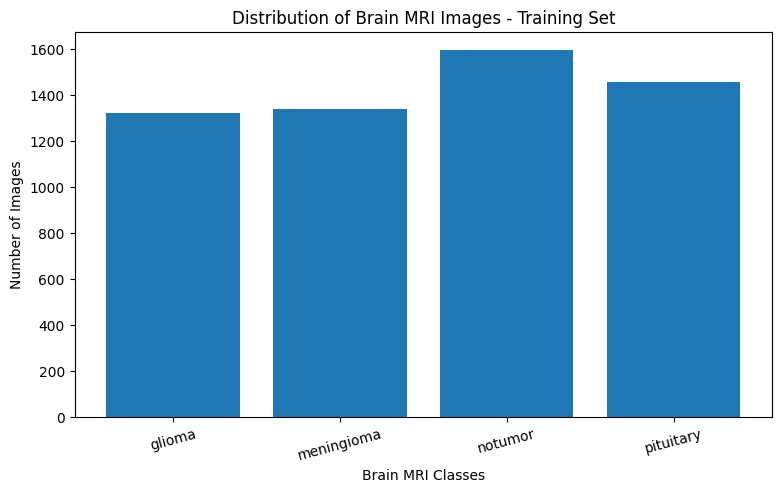

In [ ]:
import matplotlib.pyplot as plt
import os

classes = ["glioma", "meningioma", "notumor", "pituitary"]

training_counts = [
    len(os.listdir(os.path.join(dataset_path, "Training", c)))
    for c in classes
]

plt.figure(figsize=(9, 5))

plt.bar(classes, training_counts)

plt.title("Distribution of Brain MRI Images - Training Set")
plt.xlabel("Brain MRI Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)

plt.show()

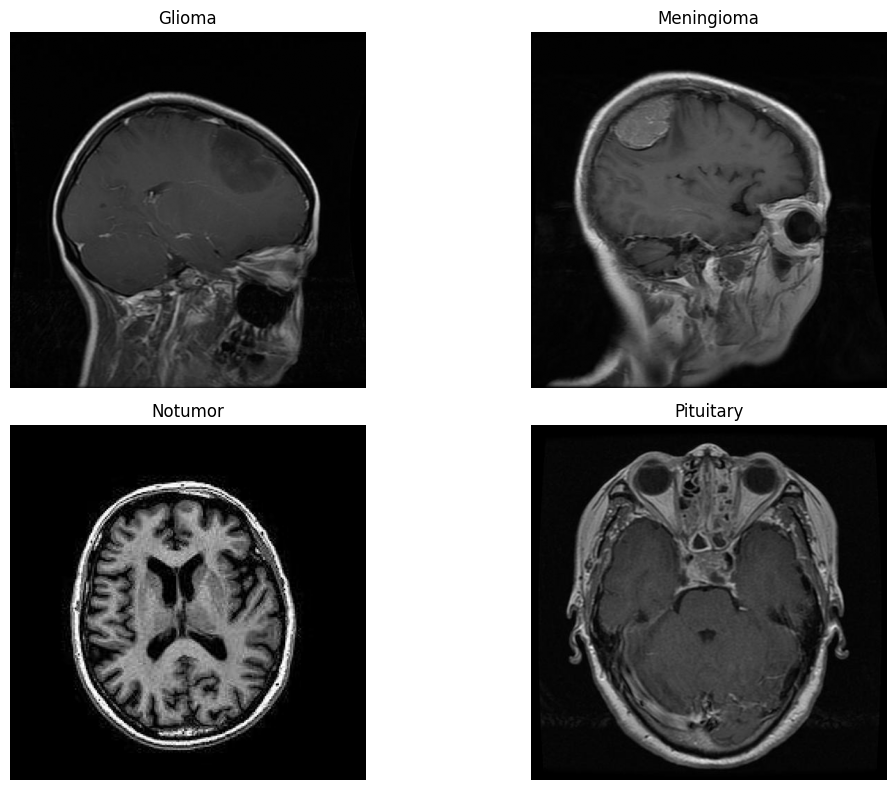

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(12, 8))

for i, category in enumerate(classes):

    folder = os.path.join(dataset_path, "Training", category)

    image_name = random.choice(os.listdir(folder))
    image_path = os.path.join(folder, image_name)

    img = Image.open(image_path)

    plt.subplot(2, 2, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(category.capitalize())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter
from PIL import Image

dimensions = Counter()

for category in classes:

    folder = os.path.join(dataset_path, "Training", category)

    for image_name in os.listdir(folder):

        image_path = os.path.join(folder, image_name)

        try:
            img = Image.open(image_path)
            dimensions[img.size] += 1

        except Exception:
            print("Image illisible :", image_path)

print("Les dimensions les plus fréquentes :")

for size, count in dimensions.most_common(10):
    print(size, ":", count, "images")

Les dimensions les plus fréquentes :
(512, 512) : 3955 images
(225, 225) : 268 images
(630, 630) : 77 images
(236, 236) : 53 images
(201, 251) : 43 images
(300, 168) : 38 images
(228, 221) : 38 images
(442, 442) : 37 images
(150, 198) : 36 images
(232, 217) : 35 images


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "Training"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    label_mode="categorical"
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "Training"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    label_mode="categorical"
)

Found 5712 files belonging to 4 classes.
Using 4570 files for training.
Found 5712 files belonging to 4 classes.
Using 1142 files for validation.


In [ ]:
print("Classes :", train_dataset.class_names)

Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

In [ ]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "Testing"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="categorical"
)
test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

Found 1311 files belonging to 4 classes.


In [ ]:
print("Training batches :", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches :", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Testing batches :", tf.data.experimental.cardinality(test_dataset).numpy())
for images, labels in train_dataset.take(1):
    print("Image shape :", images.shape)
    print("Label shape :", labels.shape)
    print("Pixel minimum :", tf.reduce_min(images).numpy())
    print("Pixel maximum :", tf.reduce_max(images).numpy())

Training batches : 143
Validation batches : 36
Testing batches : 41
Image shape : (32, 224, 224, 3)
Label shape : (32, 4)
Pixel minimum : 0.0
Pixel maximum : 1.0


In [ ]:
from tensorflow.keras import layers, models

In [ ]:
model = models.Sequential([

    # Input
    layers.Input(shape=(224, 224, 3)),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Output
    layers.Dense(4, activation='softmax')
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
label_mode="categorical"

In [ ]:
print("Model ready!")
model.summary()

Model ready!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 44s 211ms/step - accuracy: 0.6869 - loss: 0.7707 - val_accuracy: 0.8266 - val_loss: 0.4856
Epoch 2/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - accuracy: 0.8392 - loss: 0.4165 - val_accuracy: 0.8818 - val_loss: 0.3421
Epoch 3/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.8803 - loss: 0.3070 - val_accuracy: 0.9063 - val_loss: 0.2661
Epoch 4/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 105ms/step - accuracy: 0.9217 - loss: 0.2222 - val_accuracy: 0.9159 - val_loss: 0.3001
Epoch 5/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.9449 - loss: 0.1695 - val_accuracy: 0.9177 - val_loss: 0.2612
Epoch 6/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 102ms/step - accuracy: 0.9514 - loss: 0.1367 - val_accuracy: 0.9361 - val_loss: 0.2510
Epoch 7/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.9611 - loss: 0.0972 - val_accuracy: 0.9431 - val_loss: 0.2317
Epoch 8/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.9676 - loss: 0

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.9818 - loss: 0.0516 - val_accuracy: 0.9475 - val_loss: 0.2402
Epoch 2/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.9829 - loss: 0.0416 - val_accuracy: 0.9457 - val_loss: 0.2437
Epoch 3/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 14s 101ms/step - accuracy: 0.9880 - loss: 0.0359 - val_accuracy: 0.9457 - val_loss: 0.2824
Epoch 4/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - accuracy: 0.9856 - loss: 0.0400 - val_accuracy: 0.9501 - val_loss: 0.2534
Epoch 5/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 105ms/step - accuracy: 0.9871 - loss: 0.0328 - val_accuracy: 0.9483 - val_loss: 0.3230
Epoch 6/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.9895 - loss: 0.0244 - val_accuracy: 0.9518 - val_loss: 0.2534
Epoch 7/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 102ms/step - accuracy: 0.9882 - loss: 0.0327 - val_accuracy: 0.9518 - val_loss: 0.2552
Epoch 8/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 106ms/step - accuracy: 0.9908 - loss: 0

In [ ]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

41/41 ━━━━━━━━━━━━━━━━━━━━ 166s 4s/step - accuracy: 0.9375 - loss: 0.3958
Test Loss: 0.3957666754722595
Test Accuracy: 0.9374523162841797


In [ ]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Nombre de vraies étiquettes :", len(y_true))
print("Nombre de prédictions :", len(y_pred))

Nombre de vraies étiquettes : 1311
Nombre de prédictions : 1311


In [ ]:
from sklearn.metrics import classification_report

class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

      glioma       0.98      0.83      0.90       300
  meningioma       0.85      0.92      0.88       306
     notumor       0.95      0.99      0.97       405
   pituitary       0.98      1.00      0.99       300

    accuracy                           0.94      1311
   macro avg       0.94      0.93      0.93      1311
weighted avg       0.94      0.94      0.94      1311



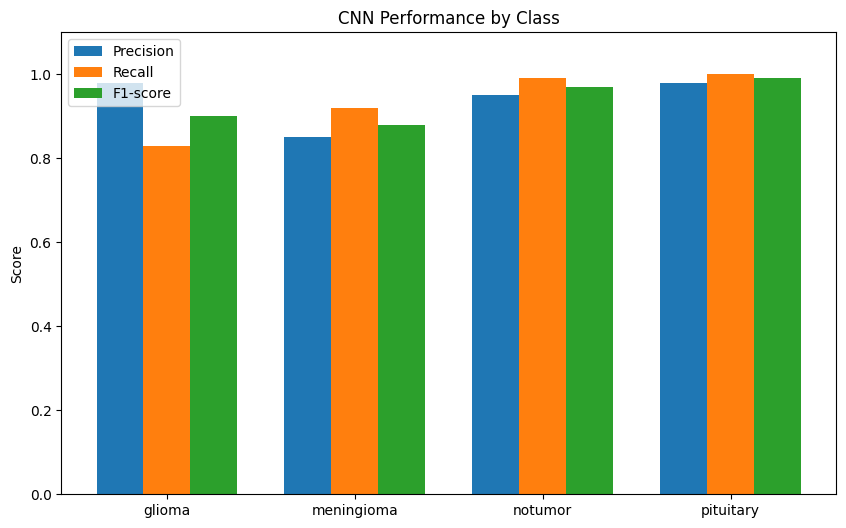

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

precision = [0.98, 0.85, 0.95, 0.98]
recall = [0.83, 0.92, 0.99, 1.00]
f1 = [0.90, 0.88, 0.97, 0.99]

x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - width, precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar(x + width, f1, width, label='F1-score')

plt.xticks(x, class_names)
plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("CNN Performance by Class")
plt.legend()
plt.show()

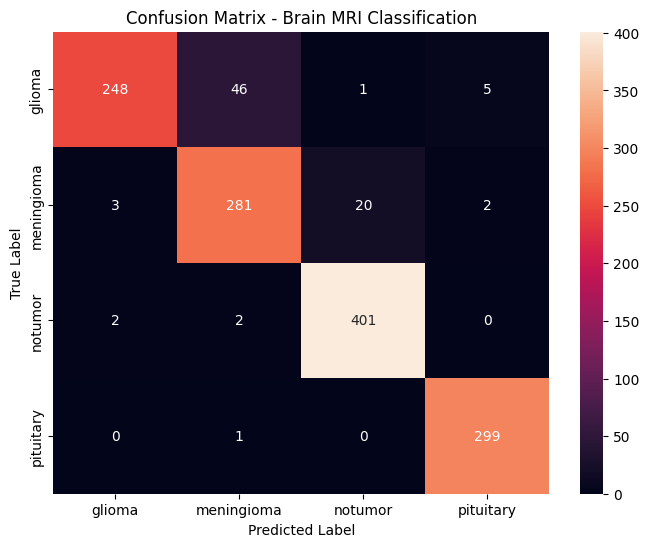

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Brain MRI Classification")

plt.show()

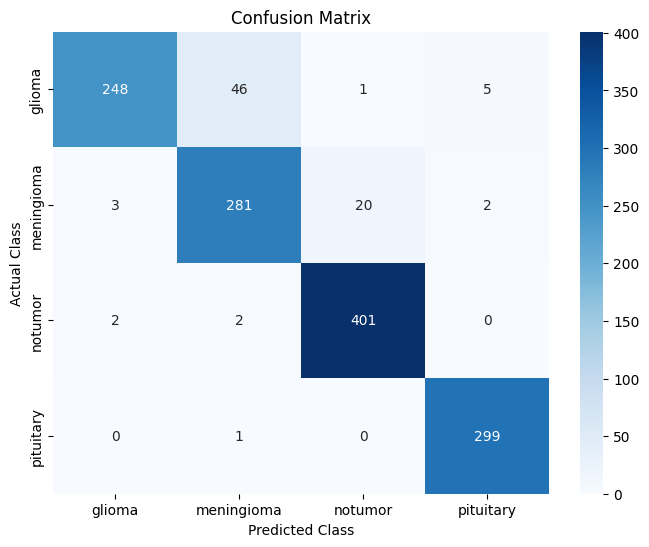

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
])
improved_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Data Augmentation
    data_augmentation,

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Global Average Pooling
    layers.GlobalAveragePooling2D(),

    # Classification
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(4, activation='softmax')
])

In [ ]:
improved_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
improved_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
history_improved = improved_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 24s 117ms/step - accuracy: 0.4201 - loss: 1.1850 - val_accuracy: 0.4387 - val_loss: 1.1006
Epoch 2/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - accuracy: 0.5838 - loss: 0.9778 - val_accuracy: 0.3879 - val_loss: 1.6065
Epoch 3/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - accuracy: 0.6289 - loss: 0.9059 - val_accuracy: 0.3862 - val_loss: 1.7745
Epoch 4/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.6600 - loss: 0.8455 - val_accuracy: 0.4772 - val_loss: 1.2278


In [ ]:
print("Epochs executed:", len(history_improved.history['loss']))

print("Best validation loss:",
      min(history_improved.history['val_loss']))

print("Best validation accuracy:",
      max(history_improved.history['val_accuracy']))

Epochs executed: 4
Best validation loss: 1.1005512475967407
Best validation accuracy: 0.4772329330444336


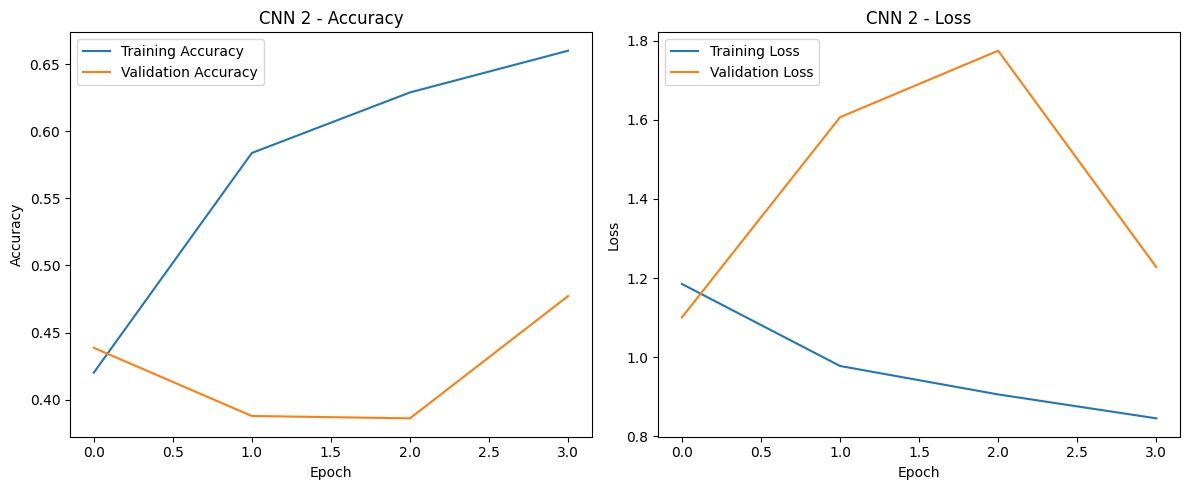

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_improved.history['accuracy'],
         label='Training Accuracy')

plt.plot(history_improved.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('CNN 2 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_improved.history['loss'],
         label='Training Loss')

plt.plot(history_improved.history['val_loss'],
         label='Validation Loss')

plt.title('CNN 2 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
cnn3 = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(4, activation='softmax')
])

In [ ]:
cnn3.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        'best_cnn3.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

In [ ]:
history_cnn3 = cnn3.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 22s 125ms/step - accuracy: 0.6589 - loss: 0.8197 - val_accuracy: 0.8468 - val_loss: 0.4522
Epoch 2/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - accuracy: 0.8287 - loss: 0.4366 - val_accuracy: 0.8940 - val_loss: 0.3076
Epoch 3/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 16s 108ms/step - accuracy: 0.8823 - loss: 0.3189 - val_accuracy: 0.8949 - val_loss: 0.2839
Epoch 4/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 21s 114ms/step - accuracy: 0.9109 - loss: 0.2398 - val_accuracy: 0.9098 - val_loss: 0.2685
Epoch 5/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 19s 104ms/step - accuracy: 0.9341 - loss: 0.1859 - val_accuracy: 0.9335 - val_loss: 0.2174
Epoch 6/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 102ms/step - accuracy: 0.9429 - loss: 0.1543 - val_accuracy: 0.9282 - val_loss: 0.2259
Epoch 7/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 105ms/step - accuracy: 0.9597 - loss: 0.1125 - val_accuracy: 0.9291 - val_loss: 0.2455
Epoch 8/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - accuracy: 0.9678 - loss: 0

In [ ]:
print("Epochs executed:",
      len(history_cnn3.history['loss']))

print("Best validation accuracy:",
      max(history_cnn3.history['val_accuracy']))

print("Best validation loss:",
      min(history_cnn3.history['val_loss']))
print("Best model saved:",
      os.path.exists("best_cnn3.keras"))

Epochs executed: 11
Best validation accuracy: 0.9369527101516724
Best validation loss: 0.20386259257793427
Best model saved: True


In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# Vraies classes
y_val_true = []
for images, labels in validation_dataset:
    y_val_true.extend(np.argmax(labels.numpy(), axis=1))

y_val_true = np.array(y_val_true)

# Prédictions CNN 1
y_val_pred_cnn1 = np.argmax(
    model.predict(validation_dataset, verbose=0), axis=1
)

# Prédictions CNN 3
y_val_pred_cnn3 = np.argmax(
    cnn3.predict(validation_dataset, verbose=0), axis=1
)

print("===== CNN 1 =====")
print(classification_report(
    y_val_true, y_val_pred_cnn1, target_names=class_names
))

print("===== CNN 3 =====")
print(classification_report(
    y_val_true, y_val_pred_cnn3, target_names=class_names
))

===== CNN 1 =====
              precision    recall  f1-score   support

      glioma       0.24      0.21      0.22       244
  meningioma       0.26      0.27      0.26       249
     notumor       0.30      0.30      0.30       348
   pituitary       0.28      0.28      0.28       301

    accuracy                           0.27      1142
   macro avg       0.27      0.27      0.27      1142
weighted avg       0.27      0.27      0.27      1142

===== CNN 3 =====
              precision    recall  f1-score   support

      glioma       0.18      0.16      0.17       244
  meningioma       0.19      0.20      0.20       249
     notumor       0.30      0.30      0.30       348
   pituitary       0.27      0.27      0.27       301

    accuracy                           0.24      1142
   macro avg       0.23      0.23      0.23      1142
weighted avg       0.24      0.24      0.24      1142



In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true = []
y_pred_cnn1 = []
y_pred_cnn3 = []

for images, labels in validation_dataset:

    # Vraies étiquettes
    y_true.extend(np.argmax(labels.numpy(), axis=1))

    # Prédictions CNN 1
    predictions1 = model(images, training=False)
    y_pred_cnn1.extend(
        np.argmax(predictions1.numpy(), axis=1)
    )

    # Prédictions CNN 3
    predictions3 = cnn3(images, training=False)
    y_pred_cnn3.extend(
        np.argmax(predictions3.numpy(), axis=1)
    )

y_true = np.array(y_true)
y_pred_cnn1 = np.array(y_pred_cnn1)
y_pred_cnn3 = np.array(y_pred_cnn3)

print("===== CNN 1 =====")
print(classification_report(
    y_true, y_pred_cnn1, target_names=class_names
))

print("===== CNN 3 =====")
print(classification_report(
    y_true, y_pred_cnn3, target_names=class_names
))

===== CNN 1 =====
              precision    recall  f1-score   support

      glioma       0.98      0.86      0.91       244
  meningioma       0.86      0.91      0.88       249
     notumor       0.94      0.97      0.96       348
   pituitary       0.98      0.99      0.99       301

    accuracy                           0.94      1142
   macro avg       0.94      0.93      0.94      1142
weighted avg       0.94      0.94      0.94      1142

===== CNN 3 =====
              precision    recall  f1-score   support

      glioma       0.96      0.89      0.93       244
  meningioma       0.85      0.90      0.87       249
     notumor       0.95      0.96      0.96       348
   pituitary       0.98      0.98      0.98       301

    accuracy                           0.94      1142
   macro avg       0.94      0.93      0.93      1142
weighted avg       0.94      0.94      0.94      1142



In [ ]:
model.save("brain_tumor_cnn1.keras")

print("Modèle CNN 1 sauvegardé avec succès !")

Modèle CNN 1 sauvegardé avec succès !


In [ ]:
from google.colab import files

files.download("brain_tumor_cnn1.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Évaluation du modèle sur les données de test

test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 127ms/step - accuracy: 0.9375 - loss: 0.3958
Test Loss: 0.3957666754722595
Test Accuracy: 93.74523162841797 %


              precision    recall  f1-score   support

      glioma       0.98      0.83      0.90       300
  meningioma       0.85      0.92      0.88       306
     notumor       0.95      0.99      0.97       405
   pituitary       0.98      1.00      0.99       300

    accuracy                           0.94      1311
   macro avg       0.94      0.93      0.93      1311
weighted avg       0.94      0.94      0.94      1311



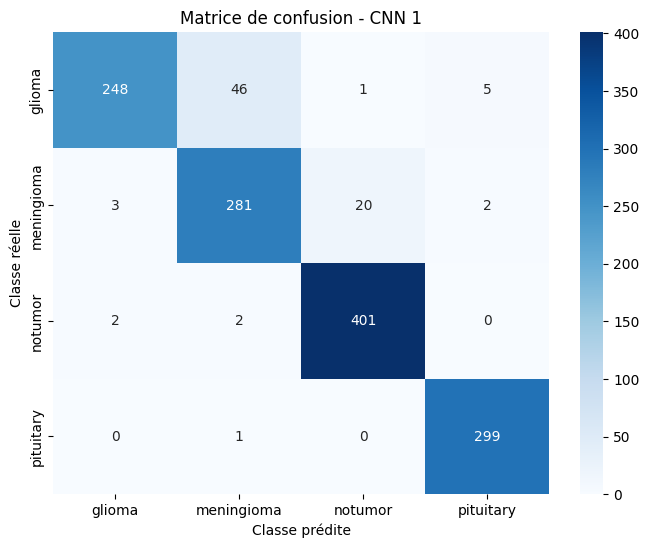

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

y_true_test = []
y_pred_test = []

for images, labels in test_dataset:

    # Vraies classes
    y_true_test.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    # Prédictions du modèle
    predictions = model(images, training=False)

    y_pred_test.extend(
        np.argmax(predictions.numpy(), axis=1)
    )

y_true_test = np.array(y_true_test)
y_pred_test = np.array(y_pred_test)

# Rapport de classification
print(classification_report(
    y_true_test,
    y_pred_test,
    target_names=class_names
))

# Matrice de confusion
cm = confusion_matrix(y_true_test, y_pred_test)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion - CNN 1")
plt.show()

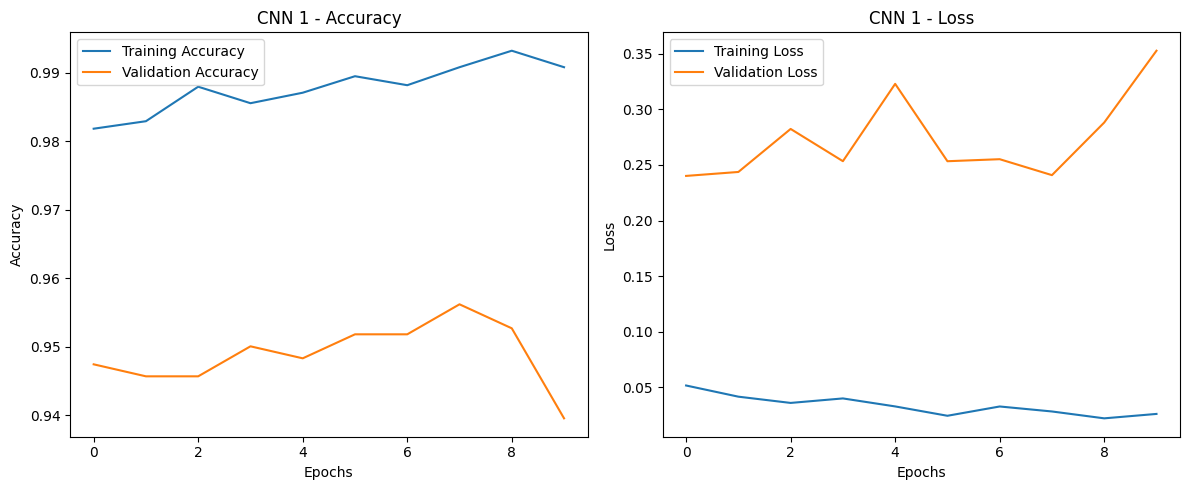

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN 1 - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN 1 - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf

loaded_model = tf.keras.models.load_model(
    "/content/brain_tumor_cnn1.keras"
)

print("Modèle chargé avec succès !")

loaded_model.summary()

Modèle chargé avec succès !


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,508,430 (127.82 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,954 (85.22 MB)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Tr-me_0019.jpg to Tr-me_0019.jpg


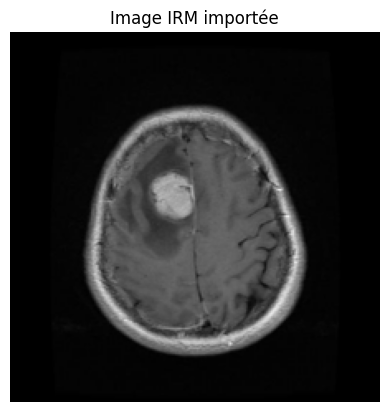

Shape de l'image : (1, 224, 224, 3)


In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Récupérer le nom de l'image importée
image_path = list(uploaded.keys())[0]

# Ouvrir et préparer l'image
img = Image.open(image_path).convert("RGB")
img = img.resize((224, 224))

# Afficher l'image
plt.imshow(img)
plt.title("Image IRM importée")
plt.axis("off")
plt.show()

# Conversion en tableau NumPy
img_array = np.array(img)

# Normalisation
img_array = img_array / 255.0

# Ajouter la dimension du batch
img_array = np.expand_dims(img_array, axis=0)

print("Shape de l'image :", img_array.shape)

In [ ]:
# Classes du modèle
class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

# Prédiction
predictions = loaded_model.predict(img_array)

# Classe ayant la probabilité la plus élevée
predicted_class = np.argmax(predictions[0])

# Affichage
print("Classe prédite :", class_names[predicted_class])
print("Probabilité associée :",
      round(float(predictions[0][predicted_class]) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Classe prédite : meningioma
Probabilité associée : 100.0 %


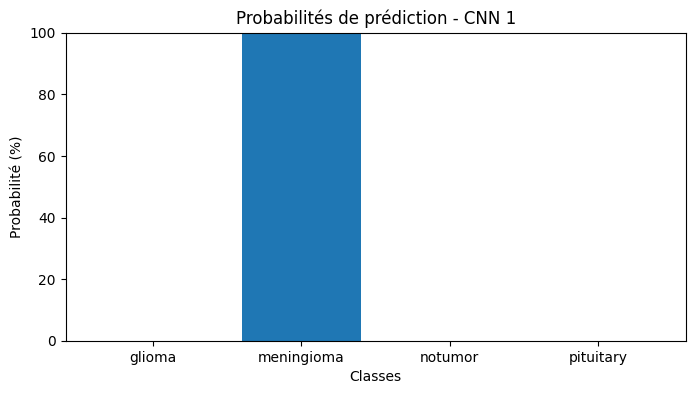

In [ ]:
plt.figure(figsize=(8, 4))

plt.bar(class_names, predictions[0] * 100)

plt.title("Probabilités de prédiction - CNN 1")
plt.xlabel("Classes")
plt.ylabel("Probabilité (%)")
plt.ylim(0, 100)

plt.show()

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr
import numpy as np
from PIL import Image

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

def classify_image(image):

    # Redimensionner l'image
    image = image.convert("RGB")
    image = image.resize((224, 224))

    # Normaliser l'image
    image_array = np.array(image) / 255.0

    # Ajouter la dimension batch
    image_array = np.expand_dims(image_array, axis=0)

    # Effectuer la prédiction
    predictions = loaded_model.predict(image_array, verbose=0)[0]

    # Associer chaque classe à son score
    results = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    return results

In [ ]:
interface = gr.Interface(
    fn=classify_image,

    inputs=gr.Image(
        type="pil",
        label="Upload a Brain MRI Image"
    ),

    outputs=gr.Label(
        num_top_classes=4,
        label="Classification Results"
    ),

    title="Brain MRI Tumor Classification",

    description=(
        "Upload a brain MRI image to classify it "
        "into one of four categories: Glioma, "
        "Meningioma, No Tumor or Pituitary."
    )
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4fdedafddb25553f0b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
